## 1. Install Dependencies

In [1]:
!pip install -q legacy-cgi opendatasets ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.1 MB/s eta 0:00:00


## 2. Import Libraries

In [2]:
import os
import glob
import shutil
import random
import zipfile
from pathlib import Path

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import opendatasets as od
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


## 3. Download the Full Kitchenware Dataset (Kaggle)
Needed later for the batch-inference step, which runs the trained model over every remaining raw image.

In [3]:
RAW_DIR = 'kitchenware-classification'

if Path(RAW_DIR).is_dir():
    print('The dataset already exists. Skipping download...')
else:
    print('Downloading the dataset...')
    od.download('https://www.kaggle.com/competitions/kitchenware-classification/data')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: raunakgola
Your Kaggle Key: ··········


100%|██████████| 1.63G/1.63G [01:36<00:00, 18.1MB/s]



Extracting archive ./kitchenware-classification/kitchenware-classification.zip to ./kitchenware-classification


## 4. Unzip the Annotated Training Subset and Build the YOLO data.yaml
Upload `sample_900.zip` to Colab first (drag into the Files panel, or use `files.upload()`), then run this.

In [4]:
ZIP_PATH = "/content/sample_900.zip"
EXTRACT_DIR = "/content/sample_900"

if not os.path.isdir(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall("/content")
    print(f"Extracted to {EXTRACT_DIR}")
else:
    print("Already extracted, skipping.")

img_dir = os.path.join(EXTRACT_DIR, "images")
lbl_dir = os.path.join(EXTRACT_DIR, "labels")
print("Images found:", len(glob.glob(f"{img_dir}/*.jpg")))
print("Labels found:", len(glob.glob(f"{lbl_dir}/*.txt")))

# Order matches how class_id was assigned when the .txt label files were written
CLASS_NAMES = ["plate", "spoon", "fork", "knife", "cup", "glass"]

# images/ and labels/ sit side by side inside sample_900, which is exactly
# the layout Ultralytics expects -- it finds labels by swapping "images" for
# "labels" in the given path, so no restructuring/copying is needed here.
yaml_content = f"""\
path: {EXTRACT_DIR}
train: images
val: images
nc: {len(CLASS_NAMES)}
names: {CLASS_NAMES}
"""

YAML_PATH = "/content/kitchenware.yaml"
with open(YAML_PATH, "w") as f:
    f.write(yaml_content)

print(f"Wrote {YAML_PATH}:\n{yaml_content}")

Extracted to /content/sample_900
Images found: 887
Labels found: 887
Wrote /content/kitchenware.yaml:
path: /content/sample_900
train: images
val: images
nc: 6
names: ['plate', 'spoon', 'fork', 'knife', 'cup', 'glass']



## 5. Train YOLOv8s with Early Stopping

In [5]:
model = YOLO("yolov8s.pt")

results = model.train(
    data=YAML_PATH,
    epochs=70,
    imgsz=640,
    batch=64,
    workers=2,
    patience=7,   # stop early if validation metrics show no improvement for 5 straight epochs
    project="/content/runs",
    name="yolov8s_seed"
)

Ultralytics 8.4.138 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kitchenware.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=70, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_seed, nbs=64, nms=False, opse

## 6. View Training Metrics (Curves, Confusion Matrix, PR Curve, F1 Curve)

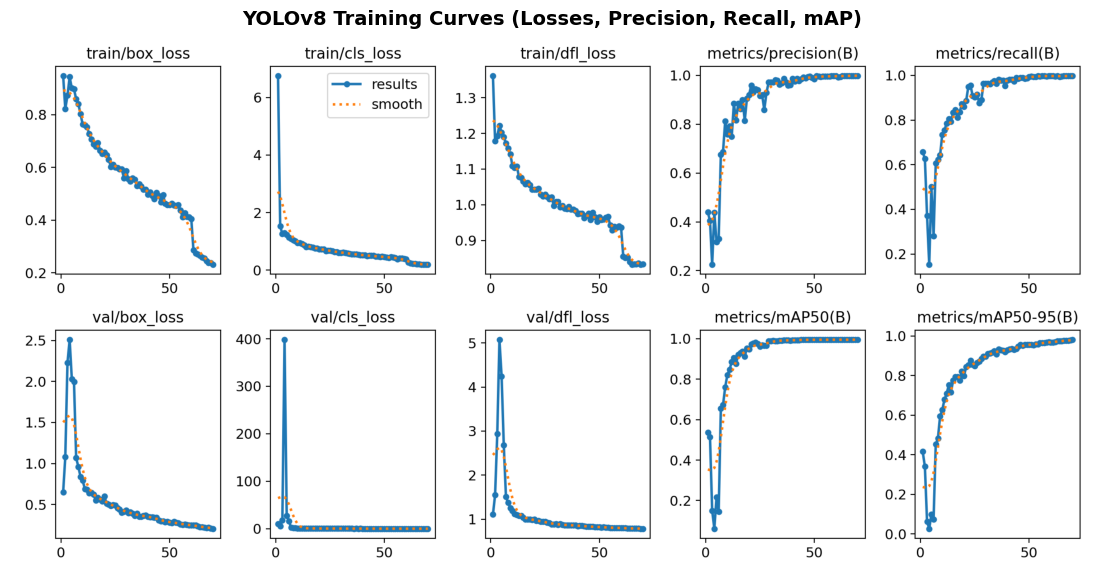

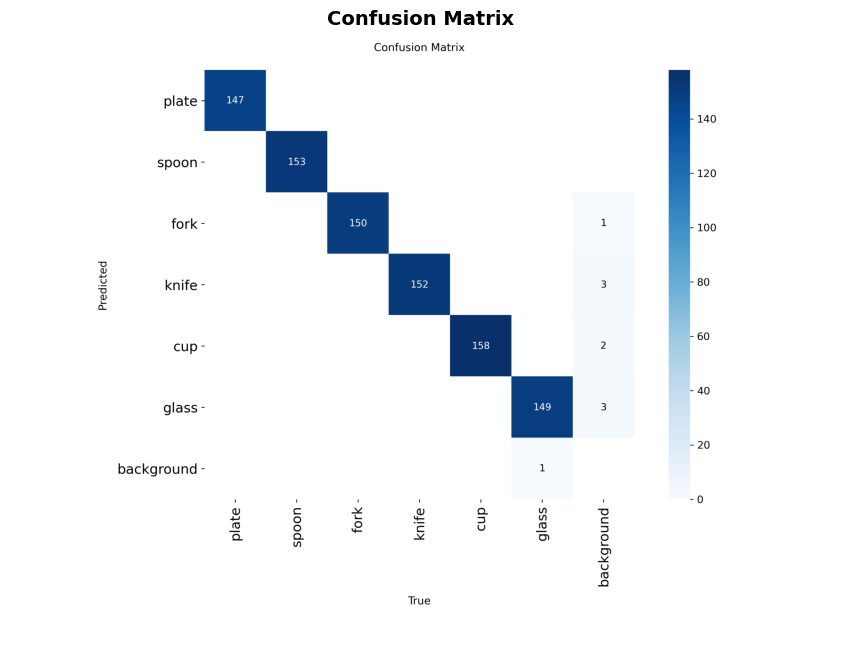

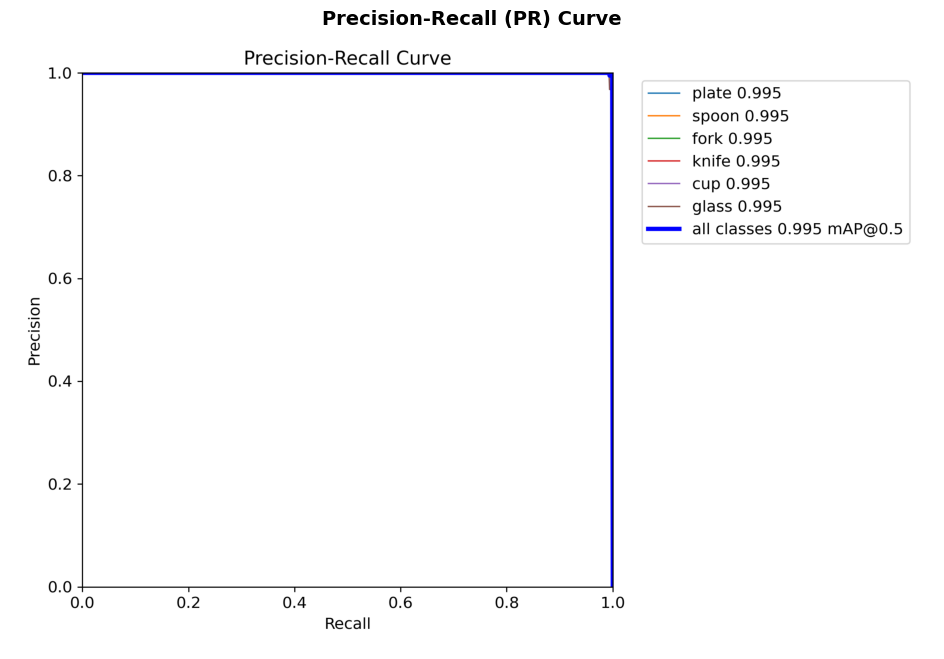

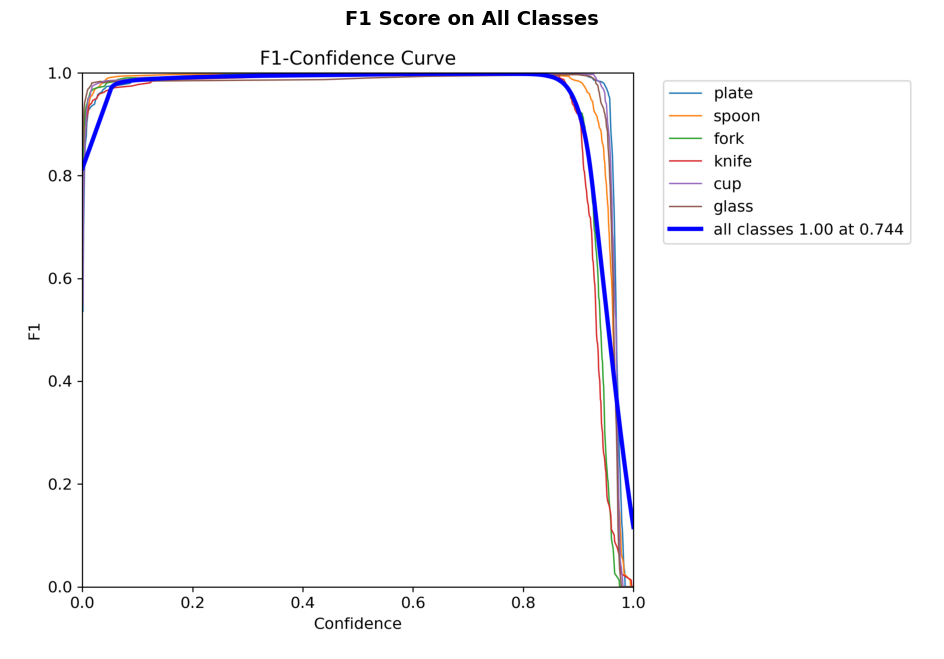

In [6]:
RUN_DIR = "/content/runs/yolov8s_seed"
# If Ultralytics nested it under detect/, uncomment instead:
# RUN_DIR = "/content/runs/detect/yolov8s_seed"

def display_yolo_image(image_name, title):
    img_path = os.path.join(RUN_DIR, image_name)
    if os.path.exists(img_path):
        img = cv.imread(img_path)
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        plt.figure(figsize=(14, 8))
        plt.imshow(img)
        plt.title(title, fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.show()
    else:
        print(f"File not found: {img_path}")

display_yolo_image("results.png", "YOLOv8 Training Curves (Losses, Precision, Recall, mAP)")
print()
display_yolo_image("confusion_matrix.png", "Confusion Matrix")
print()
display_yolo_image("BoxPR_curve.png", "Precision-Recall (PR) Curve")
print()
display_yolo_image("BoxF1_curve.png", "F1 Score on All Classes")
print()

## 7. View Training Batch Visualizations

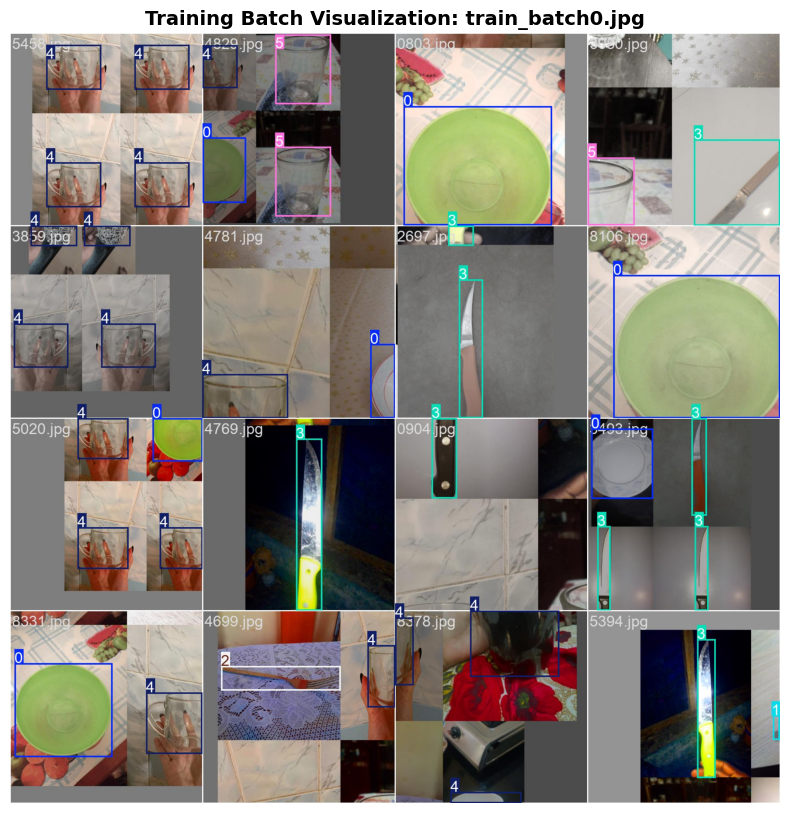

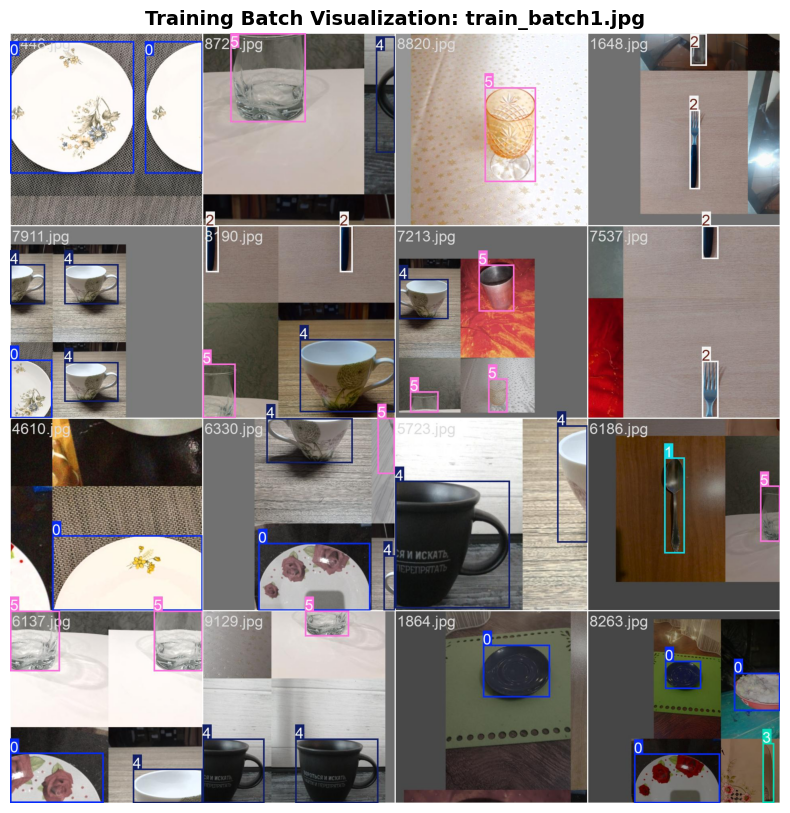

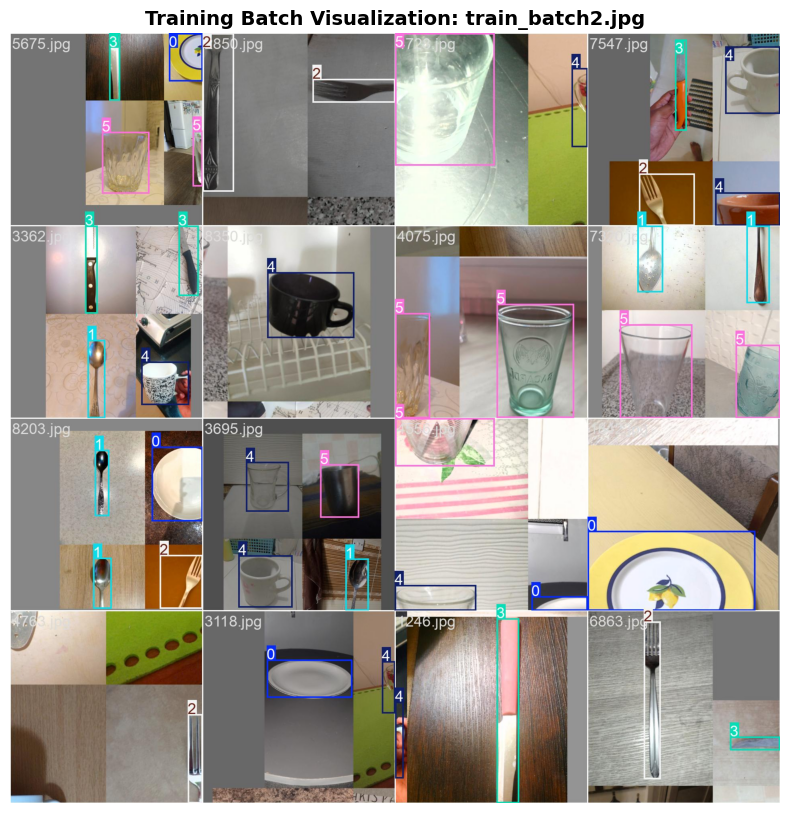

In [7]:
train_batches = sorted(glob.glob(os.path.join(RUN_DIR, "train_batch*.jpg")))

for img_path in train_batches[:3]:
    img = cv.imread(img_path)
    if img is not None:
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        plt.figure(figsize=(16, 10))
        plt.imshow(img)
        plt.title(f"Training Batch Visualization: {os.path.basename(img_path)}", fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.show()

## 8. Batch Inference on All Remaining Images (Train + Test)

In [9]:
import os
from ultralytics import YOLO

IMAGES_SRC_DIR = "/content/kitchenware-classification/images"      # folder of photos
PRED_OUTPUT_DIR = "/content/predicted_labels"
os.makedirs(PRED_OUTPUT_DIR, exist_ok=True)

trained_model = YOLO("/content/runs/yolov8s_seed/weights/best.pt")

results = trained_model.predict(
    source=IMAGES_SRC_DIR,
    conf=0.30,
    iou=0.45,
    batch=128,
    device=0,
    stream=True
)

for result in results:
    img_id = os.path.splitext(os.path.basename(result.path))[0]
    boxes = result.boxes

    txt_path = f"{PRED_OUTPUT_DIR}/{img_id}.txt"
    with open(txt_path, "w") as f:
        if len(boxes) > 0:
            class_ids = boxes.cls.cpu().numpy().astype(int)
            xywhn = boxes.xywhn.cpu().numpy()
            for cls_id, (cx, cy, w, h) in zip(class_ids, xywhn):
                f.write(f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")

print(f"Done. Labels saved to {PRED_OUTPUT_DIR}")

Streaming output truncated to the last 5000 lines.
image 4370/9367 /content/kitchenware-classification/images/4369.jpg: 640x640 1 knife, 10.8ms
image 4371/9367 /content/kitchenware-classification/images/4370.jpg: 640x640 1 plate, 10.8ms
image 4372/9367 /content/kitchenware-classification/images/4371.jpg: 640x640 1 fork, 10.8ms
image 4373/9367 /content/kitchenware-classification/images/4372.jpg: 640x640 1 plate, 1 glass, 10.8ms
image 4374/9367 /content/kitchenware-classification/images/4373.jpg: 640x640 1 knife, 10.8ms
image 4375/9367 /content/kitchenware-classification/images/4374.jpg: 640x640 1 spoon, 10.8ms
image 4376/9367 /content/kitchenware-classification/images/4375.jpg: 640x640 1 glass, 10.8ms
image 4377/9367 /content/kitchenware-classification/images/4376.jpg: 640x640 1 plate, 10.8ms
image 4378/9367 /content/kitchenware-classification/images/4377.jpg: 640x640 1 knife, 10.8ms
image 4379/9367 /content/kitchenware-classification/images/4378.jpg: 640x640 1 glass, 10.8ms
image 4380/

In [10]:
label_files = os.listdir(PRED_OUTPUT_DIR)
empty_count = sum(1 for f in label_files if os.path.getsize(os.path.join(PRED_OUTPUT_DIR, f)) == 0)
print(f"Total label files: {len(label_files)} | Empty (no detections): {empty_count} | With detections: {len(label_files) - empty_count}")

Total label files: 9367 | Empty (no detections): 98 | With detections: 9269


## zip all the labels and training points

In [11]:
import os
import zipfile

ITEMS_TO_ZIP = [
    "/content/predicted_labels",
    "/content/runs",
    "/content/weights",
    "/content/kitchenware.yaml",
]

OUTPUT_ZIP = "/content/all_labels_outputs.zip"

with zipfile.ZipFile(OUTPUT_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for item in ITEMS_TO_ZIP:
        if not os.path.exists(item):
            print(f"Skipping missing path: {item}")
            continue

        if os.path.isdir(item):
            for root, _, files in os.walk(item):
                for file in files:
                    full_path = os.path.join(root, file)
                    arcname = os.path.relpath(full_path, "/content")
                    zf.write(full_path, arcname)
        else:
            zf.write(item, os.path.basename(item))

print(f"Done. Saved to {OUTPUT_ZIP}")

Done. Saved to /content/all_labels_outputs.zip
